# Case Study 4: Predicting Student Dropout and Academic Success

## Problem statement and objectives
A higher education institution wants to understand how enrollment characteristics and early academic progress are associated with the eventual outcomes **Dropout**, **Enrolled**, and **Graduate**. This notebook cleans and explores the supplied student records, tests whether first-semester grades differ by outcome, builds and evaluates multiclass logistic regression models, and translates the evidence into responsible support recommendations.

### Prediction timing matters
The outcome is measured at the end of the normal course duration. The dataset contains enrollment-time attributes and academic records from both semesters. A model that uses second-semester data cannot be described as an early prediction. Therefore, the **primary model** predicts the final outcome at the end of semester one and uses enrollment-time fields plus first-semester data only. A separate intake-only model provides an earlier baseline. Both models exclude second-semester fields and ambiguous end-period macroeconomic indicators. The target remains the eventual recorded outcome.

The supplied file is semicolon-delimited. The UCI repository describes this dataset as 4,424 student records with enrollment information and academic performance from the first and second semesters; it defines the task as three-class classification. [UCI dataset record](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success).

## Part A — Data understanding and preprocessing
### 1. Load the CSV and inspect its structure
In Colab, upload `Studentdata.csv` when prompted. Locally, place it beside the notebook or set `STUDENT_CSV_PATH` to the full file path.

In [1]:
from pathlib import Path
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import f as f_distribution
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
TARGET = "Target"

candidate_paths = []
if os.environ.get("STUDENT_CSV_PATH"):
    candidate_paths.append(Path(os.environ["STUDENT_CSV_PATH"]))
candidate_paths += [Path("Studentdata.csv"), Path("/mnt/data/Studentdata.csv")]
CSV_PATH = next((p for p in candidate_paths if p.is_file()), None)
if CSV_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError("Studentdata.csv not found. Put it beside the notebook or set STUDENT_CSV_PATH.") from exc

df = pd.read_csv(CSV_PATH, sep=";", encoding="utf-8-sig")
df.columns = df.columns.astype(str).str.strip().str.replace(r"\s+$", "", regex=True)
df[TARGET] = df[TARGET].astype("string").str.strip()
print(f"Loaded {CSV_PATH.name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Saving Studentdata.csv to Studentdata.csv
Loaded Studentdata.csv: 4,424 rows × 37 columns


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
print("Dataset dimensions:", df.shape)
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nTarget and predictor columns:")
print("Target:", TARGET)
print("Predictor count:", df.shape[1] - 1)
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nTarget labels:", sorted(df[TARGET].dropna().unique().tolist()))

Dataset dimensions: (4424, 37)

Data types:


,dtype
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64



Target and predictor columns:
Target: Target
Predictor count: 36

Missing values: 0
Duplicate rows: 0

Target labels: ['Dropout', 'Enrolled', 'Graduate']


### 2. Identify feature types and check unusual values
Integer codes such as course, nationality, application mode, occupation, and qualification are identifiers/categories, not measurements. They will be one-hot encoded. The binary indicators are kept as numeric 0/1 fields. `Application order` has an ordered meaning, so it is retained as a numeric rank. Grades, age, unit counts, and macroeconomic measures are numeric. Zero first-semester grades are retained as recorded; they may represent no achieved grade rather than missing data.

In [3]:
binary_cols = [
    "Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "International"
]
nominal_code_cols = [
    "Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"
]
ordinal_cols = ["Application order"]
assert all(c in df.columns for c in binary_cols + nominal_code_cols + ordinal_cols + [TARGET])
numeric_cols = [c for c in df.columns if c not in binary_cols + nominal_code_cols + ordinal_cols + [TARGET]]
attribute_types = pd.DataFrame({
    "Type": (["Binary indicator"] * len(binary_cols) + ["Nominal encoded category"] * len(nominal_code_cols)
             + ["Ordinal rank"] * len(ordinal_cols) + ["Numeric measurement/count"] * len(numeric_cols)),
    "Columns": binary_cols + nominal_code_cols + ordinal_cols + numeric_cols
})
display(attribute_types)

quality_checks = {
    "Binary columns containing values outside {0, 1}": {c: sorted(df[c].dropna().unique().tolist()) for c in binary_cols if not set(df[c].dropna().unique()).issubset({0, 1})},
    "Grade values outside expected 0–20 range": {c: int(((df[c] < 0) | (df[c] > 20)).sum()) for c in ["Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]},
    "Admission grades outside 0–200": int(((df["Admission grade"] < 0) | (df["Admission grade"] > 200)).sum()),
    "Age outside 16–100": int(((df["Age at enrollment"] < 16) | (df["Age at enrollment"] > 100)).sum()),
}
print("Quality checks:")
for name, value in quality_checks.items(): print(f"- {name}: {value}")
print("\nDescriptive outlier flag counts (1.5×IQR; flags are not automatically errors):")
outlier_rows = []
for c in ["Age at enrollment", "Admission grade", "Previous qualification (grade)"]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    outlier_rows.append({"Variable": c, "IQR outlier flags": int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum())})
display(pd.DataFrame(outlier_rows))

,Type,Columns
0,Binary indicator,Daytime/evening attendance
1,Binary indicator,Displaced
2,Binary indicator,Educational special needs
3,Binary indicator,Debtor
4,Binary indicator,Tuition fees up to date
5,Binary indicator,Gender
6,Binary indicator,Scholarship holder
7,Binary indicator,International
8,Nominal encoded category,Marital status
9,Nominal encoded category,Application mode


Quality checks:
- Binary columns containing values outside {0, 1}: {}
- Grade values outside expected 0–20 range: {'Curricular units 1st sem (grade)': 0, 'Curricular units 2nd sem (grade)': 0}
- Admission grades outside 0–200: 0
- Age outside 16–100: 0

Descriptive outlier flag counts (1.5×IQR; flags are not automatically errors):


,Variable,IQR outlier flags
0,Age at enrollment,441
1,Admission grade,86
2,Previous qualification (grade),179


### 3. Preprocessing decisions
The supplied data has no missing values or duplicate rows, so no rows are removed. Nominal numeric codes are one-hot encoded; continuous and binary predictors are standardized inside a Scikit-learn pipeline. Imputation is included in each pipeline as a safeguard, and it is fitted on training data only. Second-semester fields are excluded from both models to prevent future-information leakage.

## Part B — Exploratory data analysis and statistics
### 4. Outcome distribution

,Students,Percent
Target,,
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


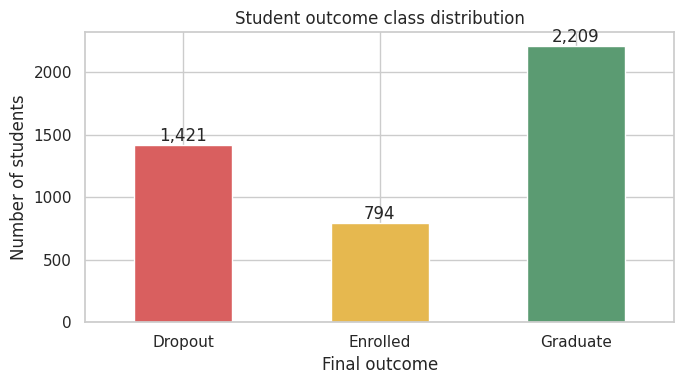

In [4]:
class_order = ["Dropout", "Enrolled", "Graduate"]
class_counts = df[TARGET].value_counts().reindex(class_order, fill_value=0)
class_summary = pd.DataFrame({"Students": class_counts, "Percent": 100 * class_counts / len(df)})
display(class_summary.round(2))
ax = class_counts.plot(kind="bar", figsize=(7, 4), color=["#d95f5f", "#e6b84f", "#5b9b72"])
ax.set(title="Student outcome class distribution", xlabel="Final outcome", ylabel="Number of students")
ax.tick_params(axis="x", rotation=0)
for bar, n in zip(ax.patches, class_counts.values): ax.annotate(f"{n:,}", (bar.get_x()+bar.get_width()/2, bar.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

### 5. Distributions of selected numerical variables

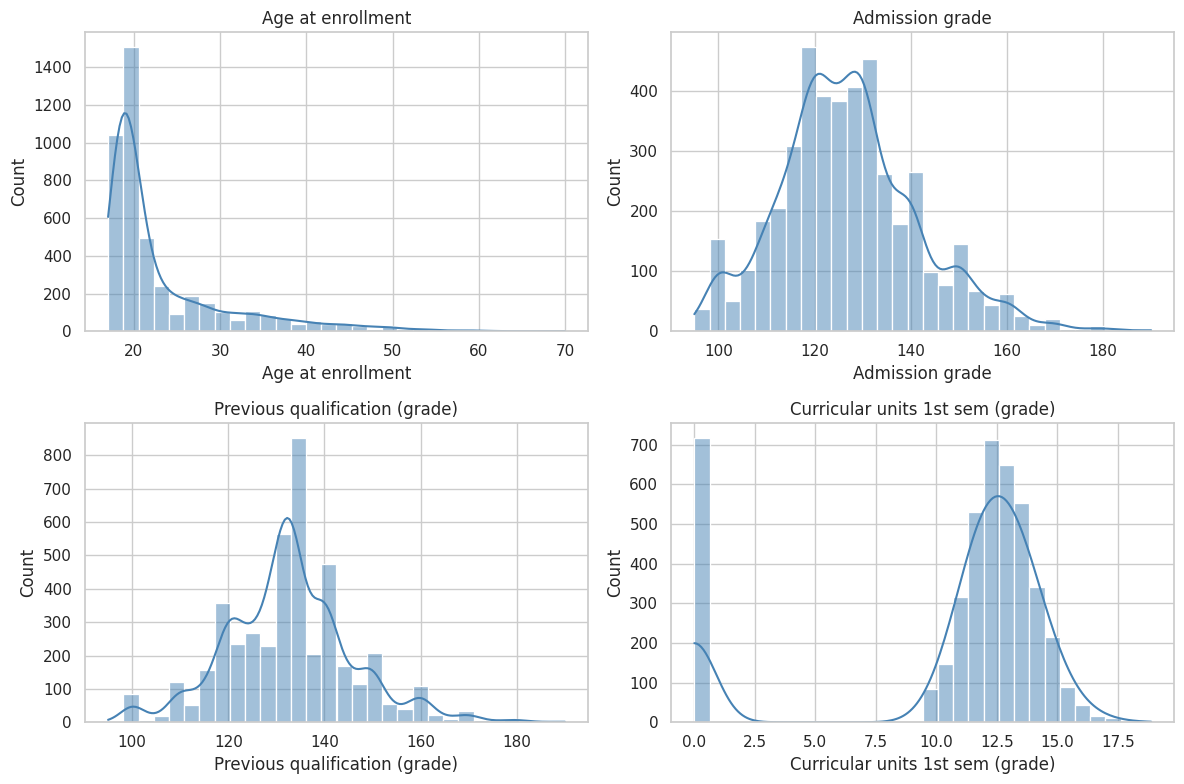

Selected numeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.27,7.59,17.0,19.0,20.00,25.0,70.00
Admission grade,4424.0,126.98,14.48,95.0,117.9,126.10,134.8,190.00
Previous qualification (grade),4424.0,132.61,13.19,95.0,125.0,133.10,140.0,190.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.0,11.0,12.29,13.4,18.88


In [5]:
hist_cols = ["Age at enrollment", "Admission grade", "Previous qualification (grade)", "Curricular units 1st sem (grade)"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, hist_cols):
    sns.histplot(data=df, x=col, bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("Selected numeric descriptive statistics:")
display(df[hist_cols].describe().T.round(2))

### 6. Admission grades and final outcomes
The box plot compares admission-grade distributions. The Kruskal–Wallis test is used as a rank-based comparison because grade distributions may be skewed and sample sizes differ. A small p-value indicates evidence of distributional differences, not that admission grade causes an outcome.

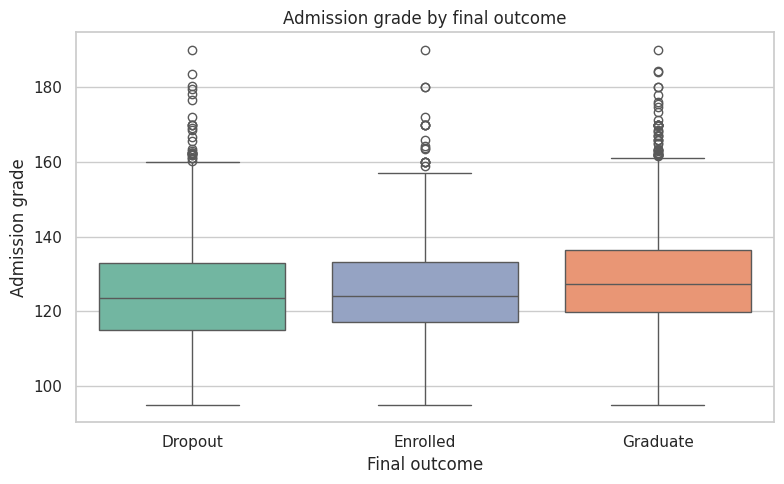

Kruskal–Wallis admission-grade comparison: H=73.235, p=1.25e-16
Group medians: {'Dropout': 123.6, 'Enrolled': 124.1, 'Graduate': 127.4}


In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=TARGET, y="Admission grade", order=class_order, hue=TARGET, legend=False, palette="Set2")
plt.title("Admission grade by final outcome"); plt.xlabel("Final outcome"); plt.ylabel("Admission grade")
plt.tight_layout(); plt.show()
admission_groups = [df.loc[df[TARGET] == label, "Admission grade"].dropna() for label in class_order]
adm_h, adm_p = stats.kruskal(*admission_groups)
print(f"Kruskal–Wallis admission-grade comparison: H={adm_h:.3f}, p={adm_p:.3g}")
print("Group medians:", df.groupby(TARGET, observed=True)["Admission grade"].median().reindex(class_order).round(2).to_dict())

### 7. First-semester performance by final outcome

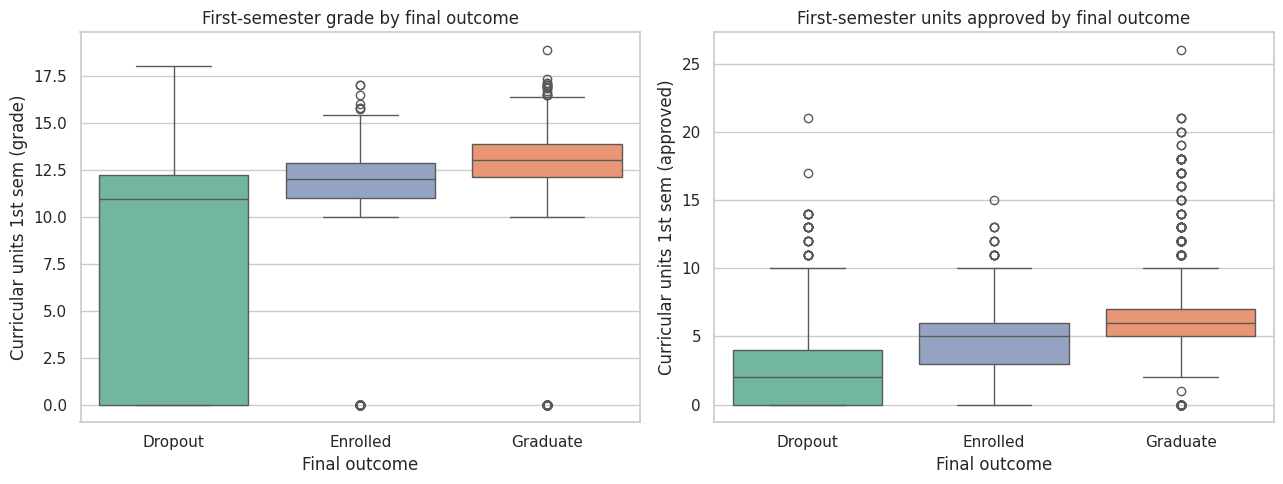

Curricular units 1st sem (grade)         \
                                     mean median   
Target                                             
Dropout                              7.26  10.93   
Enrolled                            11.13  12.00   
Graduate                            12.64  13.00   

         Curricular units 1st sem (approved)         
                                        mean median  
Target                                               
Dropout                                 2.55    2.0  
Enrolled                                4.32    5.0  
Graduate                                6.23    6.0

In [7]:
first_grade = "Curricular units 1st sem (grade)"
first_approved = "Curricular units 1st sem (approved)"
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x=TARGET, y=first_grade, order=class_order, hue=TARGET, legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("First-semester grade by final outcome"); axes[0].set_xlabel("Final outcome")
sns.boxplot(data=df, x=TARGET, y=first_approved, order=class_order, hue=TARGET, legend=False, palette="Set2", ax=axes[1])
axes[1].set_title("First-semester units approved by final outcome"); axes[1].set_xlabel("Final outcome")
plt.tight_layout(); plt.show()
first_sem_summary = df.groupby(TARGET, observed=True)[[first_grade, first_approved]].agg(["mean", "median"]).reindex(class_order).round(2)
display(first_sem_summary)

### 8. Age and outcome mix
Age bands are descriptive groupings for communication, not thresholds for decisions. The chart shows within-band outcome percentages so different group sizes are comparable.

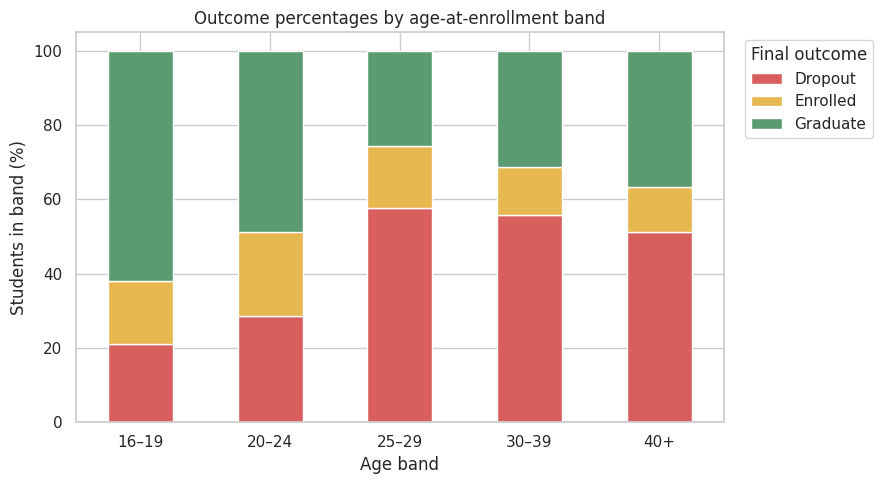

Dropout share by age band:


,Dropout percent
Age band,
16–19,21.0
20–24,28.6
25–29,57.6
30–39,55.7
40+,51.2


Age-band/outcome association: chi-square=454.06, df=8, p=4.98e-93, Cramér's V=0.227


In [8]:
age_bins = [16, 20, 25, 30, 40, 100]
age_labels = ["16–19", "20–24", "25–29", "30–39", "40+"]
df["Age band"] = pd.cut(df["Age at enrollment"], bins=age_bins, labels=age_labels, right=False)
age_mix = pd.crosstab(df["Age band"], df[TARGET], normalize="index").reindex(columns=class_order)
ax = (100 * age_mix).plot(kind="bar", stacked=True, figsize=(9, 5), color=["#d95f5f", "#e6b84f", "#5b9b72"])
ax.set(title="Outcome percentages by age-at-enrollment band", xlabel="Age band", ylabel="Students in band (%)")
ax.legend(title="Final outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Dropout share by age band:")
display((100 * age_mix["Dropout"]).round(1).rename("Dropout percent").to_frame())
chi2_age, p_age, dof_age, _ = stats.chi2_contingency(pd.crosstab(df["Age band"], df[TARGET]))
cramers_v_age = np.sqrt(chi2_age / (len(df) * min(pd.crosstab(df["Age band"], df[TARGET]).shape[0]-1, pd.crosstab(df["Age band"], df[TARGET]).shape[1]-1)))
print(f"Age-band/outcome association: chi-square={chi2_age:.2f}, df={dof_age}, p={p_age:.3g}, Cramér's V={cramers_v_age:.3f}")

### 9. Evidence-based EDA findings
The summary below uses actual values from this file. Statistical association is not evidence of causation.

In [9]:
dropout_rate = class_counts["Dropout"] / len(df)
mean_grade_by_outcome = df.groupby(TARGET, observed=True)[first_grade].mean().reindex(class_order)
mean_approved_by_outcome = df.groupby(TARGET, observed=True)[first_approved].mean().reindex(class_order)
print(f"1. Outcomes are imbalanced: Graduate {class_summary.loc['Graduate','Percent']:.1f}%, Dropout {class_summary.loc['Dropout','Percent']:.1f}%, Enrolled {class_summary.loc['Enrolled','Percent']:.1f}%.")
print("2. Mean first-semester grade by outcome:", mean_grade_by_outcome.round(2).to_dict())
print("3. Mean first-semester units approved by outcome:", mean_approved_by_outcome.round(2).to_dict())
print("4. Admission-grade group medians:", df.groupby(TARGET, observed=True)["Admission grade"].median().reindex(class_order).round(2).to_dict())
print("5. Dropout percentages by age band:", (100 * age_mix["Dropout"]).round(1).to_dict())

1. Outcomes are imbalanced: Graduate 49.9%, Dropout 32.1%, Enrolled 17.9%.
2. Mean first-semester grade by outcome: {'Dropout': 7.26, 'Enrolled': 11.13, 'Graduate': 12.64}
3. Mean first-semester units approved by outcome: {'Dropout': 2.55, 'Enrolled': 4.32, 'Graduate': 6.23}
4. Admission-grade group medians: {'Dropout': 123.6, 'Enrolled': 124.1, 'Graduate': 127.4}
5. Dropout percentages by age band: {'16–19': 21.0, '20–24': 28.6, '25–29': 57.6, '30–39': 55.7, '40+': 51.2}


## Part C — Hypothesis test: first-semester grades
**Null hypothesis (H₀):** the population mean first-semester grade is equal for Dropout, Enrolled, and Graduate outcomes.  
**Alternative hypothesis (H₁):** at least one outcome group has a different mean first-semester grade.

Welch’s one-way ANOVA is used at α = 0.05. It does not assume equal variances. Its assumptions are independent student records, a numeric outcome, and approximately normal within-group residuals (or sufficiently large samples for the mean comparison to be robust). We check variance differences with Levene’s test and inspect group distributions above. The dataset is observational, so results describe association, not causation. A small p-value is not itself a measure of practical importance; report η² and group means as context.

In [10]:
grade_groups = [df.loc[df[TARGET] == label, first_grade].dropna().to_numpy(dtype=float) for label in class_order]
# Levene's median-centered test is robust to non-normality.
lev_stat, lev_p = stats.levene(*grade_groups, center="median")
# Welch ANOVA calculation (allows unequal group variances).
k = len(grade_groups)
ns = np.array([len(g) for g in grade_groups], dtype=float)
means = np.array([g.mean() for g in grade_groups])
variances = np.array([g.var(ddof=1) for g in grade_groups])
weights = ns / variances
weighted_mean = np.sum(weights * means) / np.sum(weights)
A = np.sum((1 - weights / weights.sum()) ** 2 / (ns - 1))
welch_F = (np.sum(weights * (means - weighted_mean) ** 2) / (k - 1)) / (1 + (2 * (k - 2) / (k**2 - 1)) * A)
df1 = k - 1
df2 = (k**2 - 1) / (3 * A)
welch_p = f_distribution.sf(welch_F, df1, df2)
# Descriptive eta-squared gives a scale for group separation, not causal effect.
all_grade = df[first_grade].to_numpy(dtype=float)
grand_mean = all_grade.mean()
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in grade_groups)
ss_total = np.sum((all_grade - grand_mean)**2)
eta_squared = ss_between / ss_total
print(f"Levene's test: statistic={lev_stat:.3f}, p={lev_p:.3g}; equal-variance assumption {'not supported' if lev_p < .05 else 'not rejected'}.")
print(f"Welch ANOVA: F({df1}, {df2:.1f})={welch_F:.3f}, p={welch_p:.3g}, alpha=0.05")
print(f"Eta-squared (descriptive effect size): {eta_squared:.3f}")
print("Group sample sizes:", dict(zip(class_order, ns.astype(int))))
print("Group means:", dict(zip(class_order, means.round(2))))
print("Conclusion:", "Reject H0; evidence suggests at least one group mean differs." if welch_p < .05 else "Do not reject H0; this test did not detect a mean difference at alpha=.05." )

Levene's test: statistic=549.869, p=5.47e-214; equal-variance assumption not supported.
Welch ANOVA: F(2, 1755.4)=522.433, p=9.61e-179, alpha=0.05
Eta-squared (descriptive effect size): 0.244
Group sample sizes: {'Dropout': np.int64(1421), 'Enrolled': np.int64(794), 'Graduate': np.int64(2209)}
Group means: {'Dropout': np.float64(7.26), 'Enrolled': np.float64(11.13), 'Graduate': np.float64(12.64)}
Conclusion: Reject H0; evidence suggests at least one group mean differs.


## Part D — Multiclass logistic regression
### 10. Define two realistic prediction times
- **Intake-only comparison:** uses enrollment and prior-education information; excludes all semester academic records and macroeconomic fields whose exact measurement timing is ambiguous.
- **Primary early-warning model:** predicts the eventual outcome at the end of semester one, using intake predictors plus first-semester records. All second-semester variables are excluded.

A stratified 80/20 train/test split preserves class proportions. Encoding, imputation, scaling, and model fitting are contained in a pipeline so preprocessing is learned from the training data only. `class_weight='balanced'` gives minority classes greater influence during fitting; the held-out per-class and macro metrics still determine whether this helped.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

second_sem_cols = [c for c in df.columns if c.startswith("Curricular units 2nd sem")]
first_sem_cols = [c for c in df.columns if c.startswith("Curricular units 1st sem")]
macro_cols = ["Unemployment rate", "Inflation rate", "GDP"]
intake_features = [c for c in df.columns if c != TARGET and c != "Age band" and c not in first_sem_cols + second_sem_cols + macro_cols]
primary_features = intake_features + first_sem_cols
assert not set(second_sem_cols).intersection(primary_features)
assert not set(macro_cols).intersection(primary_features)
print(f"Intake-only feature count: {len(intake_features)}")
print(f"End-of-first-semester feature count: {len(primary_features)}")
print("Excluded from both prediction models (second semester + ambiguous macro timing):", second_sem_cols + macro_cols)
y = df[TARGET].astype(str)
X_primary = df[primary_features].copy()
X_intake = df[intake_features].copy()
X_train_p, X_test_p, y_train, y_test = train_test_split(
    X_primary, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train_i, X_test_i = X_intake.loc[X_train_p.index], X_intake.loc[X_test_p.index]

# Separate feature names according to their semantic type.
nominal_model_cols = [c for c in nominal_code_cols if c in primary_features]
def make_model(feature_columns):
    cat = [c for c in nominal_code_cols if c in feature_columns]
    num = [c for c in feature_columns if c not in cat]
    prep = ColumnTransformer([
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                   ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))]), cat),
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), num),
    ])
    return Pipeline([("preprocess", prep),
                     ("classifier", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))])

intake_model = make_model(intake_features)
intake_model.fit(X_train_i, y_train)
intake_pred = intake_model.predict(X_test_i)
primary_model = make_model(primary_features)
primary_model.fit(X_train_p, y_train)
y_pred = primary_model.predict(X_test_p)
print("Train rows:", len(y_train), "| test rows:", len(y_test))
print("Training class proportions:", y_train.value_counts(normalize=True).reindex(class_order).round(3).to_dict())
print("Test class proportions:", y_test.value_counts(normalize=True).reindex(class_order).round(3).to_dict())

Intake-only feature count: 21
End-of-first-semester feature count: 27
Excluded from both prediction models (second semester + ambiguous macro timing): ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']
Train rows: 3539 | test rows: 885
Training class proportions: {'Dropout': 0.321, 'Enrolled': 0.179, 'Graduate': 0.499}
Test class proportions: {'Dropout': 0.321, 'Enrolled': 0.18, 'Graduate': 0.499}


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 5, 6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 5, 6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### 11. Test-set evaluation and confusion matrix
Macro precision, recall, and F1 weight each outcome class equally. Weighted and accuracy scores are also shown, but should not replace minority-class review. A majority-class baseline illustrates why accuracy alone can mislead.

,Accuracy,Macro precision,Macro recall,Macro F1
Intake-only,0.563,0.543,0.540,0.532
End of semester 1 (primary),0.706,0.673,0.675,0.666
Majority-class baseline,0.499,0.166,0.333,0.222



Primary model per-class classification report:


,precision,recall,f1-score,support
Dropout,0.795,0.683,0.735,284.0
Enrolled,0.389,0.572,0.463,159.0
Graduate,0.835,0.769,0.801,442.0
macro avg,0.673,0.675,0.666,885.0
weighted avg,0.742,0.706,0.719,885.0


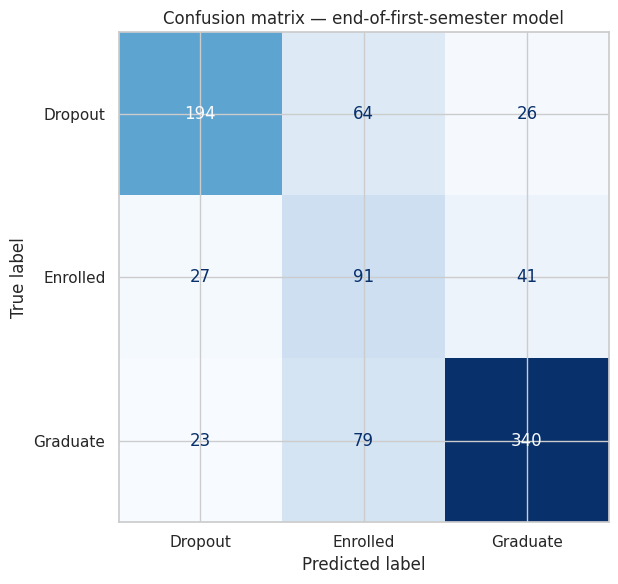

In [12]:
def model_metrics(y_true, y_hat):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_hat, labels=class_order, zero_division=0)
    return {"Accuracy": accuracy_score(y_true, y_hat), "Macro precision": p.mean(),
            "Macro recall": r.mean(), "Macro F1": f1.mean()}
majority_class = y_train.value_counts().idxmax()
majority_pred = np.repeat(majority_class, len(y_test))
comparison = pd.DataFrame({
    "Intake-only": model_metrics(y_test, intake_pred),
    "End of semester 1 (primary)": model_metrics(y_test, y_pred),
    "Majority-class baseline": model_metrics(y_test, majority_pred),
}).T
display(comparison.round(3))
print("\nPrimary model per-class classification report:")
report = classification_report(y_test, y_pred, labels=class_order, output_dict=True, zero_division=0)
per_class_report = pd.DataFrame(report).T.loc[class_order + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
display(per_class_report.round(3))
cm = confusion_matrix(y_test, y_pred, labels=class_order)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_order).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Confusion matrix — end-of-first-semester model")
plt.tight_layout(); plt.show()

### 12. Class imbalance and error patterns
Inspect recall by class to see how often each group is found, and precision by class to see how many predicted members are correct. Low recall for Dropout would mean some students who eventually dropped out were missed; low precision would mean more students are flagged than ultimately drop out. These errors have different support-planning consequences.

In [13]:
print("Test support by class:", y_test.value_counts().reindex(class_order).to_dict())
print("Per-class recall:", per_class_report.loc[class_order, "recall"].round(3).to_dict())
print("Per-class precision:", per_class_report.loc[class_order, "precision"].round(3).to_dict())
print(f"Majority-class baseline accuracy: {comparison.loc['Majority-class baseline','Accuracy']:.3f}; macro F1: {comparison.loc['Majority-class baseline','Macro F1']:.3f}.")

Test support by class: {'Dropout': 284, 'Enrolled': 159, 'Graduate': 442}
Per-class recall: {'Dropout': 0.683, 'Enrolled': 0.572, 'Graduate': 0.769}
Per-class precision: {'Dropout': 0.795, 'Enrolled': 0.389, 'Graduate': 0.835}
Majority-class baseline accuracy: 0.499; macro F1: 0.222.


## Part E — Interpretation, limitations, and recommendations
### 13. Interpret the fitted logistic regression coefficients
For a multinomial logistic model, coefficients contribute to each class's logit relative to the other classes. For numeric variables, inputs were standardized; for one-hot features, coefficients compare a category with its dropped reference category. Coefficients are predictive associations conditional on the other included fields. They are not causal effects.

In [14]:
pre = primary_model.named_steps["preprocess"]
feature_names = pre.get_feature_names_out()
coef = primary_model.named_steps["classifier"].coef_
coef_table = pd.DataFrame(coef, index=primary_model.named_steps["classifier"].classes_, columns=feature_names)
for label in class_order:
    ordered = coef_table.loc[label].sort_values()
    print(f"\n{label}: largest positive logit contributions (among fitted features)")
    display(ordered.tail(10).sort_values(ascending=False).rename("coefficient").to_frame().round(3))
    print(f"{label}: largest negative logit contributions")
    display(ordered.head(10).rename("coefficient").to_frame().round(3))


Dropout: largest positive logit contributions (among fitted features)


,coefficient
categorical__Father's occupation_90,1.136
categorical__Mother's qualification_34,0.967
categorical__Previous qualification_2,0.925
categorical__Father's qualification_40,0.880
categorical__Father's qualification_5,0.860
numeric__Curricular units 1st sem (enrolled),0.853
categorical__Course_9853,0.781
categorical__Father's qualification_22,0.776
categorical__Previous qualification_4,0.697
categorical__Course_9130,0.691


Dropout: largest negative logit contributions


,coefficient
numeric__Curricular units 1st sem (approved),-1.722
categorical__Mother's occupation_191,-1.441
categorical__Application mode_15,-1.086
categorical__Course_171,-1.056
categorical__Mother's qualification_4,-0.819
categorical__Mother's occupation_134,-0.749
categorical__Father's occupation_134,-0.663
categorical__Nacionality_25,-0.647
categorical__Father's occupation_163,-0.620
categorical__Marital status_4,-0.612



Enrolled: largest positive logit contributions (among fitted features)


...

,coefficient
categorical__Mother's occupation_90,-1.123
categorical__Mother's qualification_34,-1.106
categorical__Father's occupation_90,-1.005
categorical__Application mode_10,-0.955
categorical__Mother's qualification_9,-0.938
categorical__Father's qualification_5,-0.914
categorical__Mother's qualification_41,-0.756
categorical__Previous qualification_4,-0.752
categorical__Previous qualification_3,-0.647
categorical__Father's qualification_40,-0.634



Graduate: largest positive logit contributions (among fitted features)


,coefficient
numeric__Curricular units 1st sem (approved),2.128
categorical__Course_171,1.321
categorical__Application mode_15,1.314
categorical__Mother's occupation_90,0.944
categorical__Course_9238,0.829
categorical__Father's qualification_9,0.740
categorical__Father's qualification_11,0.728
categorical__Nacionality_26,0.664
categorical__Father's qualification_43,0.623
categorical__Course_9003,0.595


Graduate: largest negative logit contributions


,coefficient
numeric__Curricular units 1st sem (enrolled),-1.079
categorical__Course_9119,-0.944
categorical__Father's qualification_39,-0.915
categorical__Marital status_6,-0.854
categorical__Mother's occupation_8,-0.781
categorical__Course_9853,-0.781
categorical__Father's qualification_2,-0.746
categorical__Nacionality_100,-0.742
categorical__Nacionality_105,-0.694
categorical__Mother's occupation_132,-0.681


### 14. Evidence-based recommendations
Use the observed class mix, first-semester group differences, age-band pattern, and held-out error profile to prioritize **support to investigate**, not automatic decisions. Suggested actions:

1. **Offer early academic check-ins and tutoring after the first semester.** The notebook reports first-semester grades and approved units by eventual outcome; use low progress as a prompt for a supportive conversation, then validate the approach prospectively.
2. **Review course and application pathways for uneven support needs.** Course/application codes are categorical associations, not a ranking. Examine local program context and student experience before changing outreach or resources.
3. **Offer voluntary financial and administrative advising.** Check whether tuition status or debtor indicators align with outcomes in this cohort; provide navigation help without withholding enrollment or services.
4. **Use age-band patterns to test flexible scheduling and advising options.** Age is not a reason to label an individual. Co-design supports with students and measure uptake and outcomes.
5. **Use model alerts only to offer help.** Have staff review context, invite the student to opt in, and let the student correct inaccurate information. Never use a prediction to deny admission, financial aid, course access, or progression.

### Limitations and responsible use
- This is one institution and a historical observational cohort; performance may not transfer to another institution or later years.
- The target is the recorded end-of-normal-duration outcome. The notebook's primary model is timed at semester one, but no longitudinal prospective validation is performed.
- First-semester academic results are useful for a semester-one alert but are not available at initial admission. The intake-only model is the relevant comparison for that earlier time.
- `Enrolled` is a distinct recorded outcome, not necessarily a permanent final state. Student status may change after the measurement window.
- Class imbalance affects metrics. Class weighting can improve minority-class recall while lowering precision; review the actual confusion matrix and support capacity.
- Logistic regression assumes approximately linear effects in the transformed features and may miss interactions or nonlinear patterns. Feature selection, calibration, and threshold policies were not tuned on a validation set.
- Demographic and socioeconomic fields can reflect structural inequities. Predictive associations do not establish causes, and high feature importance does not justify targeting or penalizing a protected group.
- The dataset contains no intervention data, so it cannot establish which support action will improve retention. Evaluate interventions through ethical, privacy-preserving pilots.

### Conclusion
The analysis describes class imbalance, explores admission, academic, and age-related patterns, and tests the first-semester grade differences with Welch ANOVA. Logistic regression provides a reproducible multiclass baseline at two possible decision times. Any operational use should begin as a voluntary support offer, with prospective validation, subgroup fairness checks, and monitoring for changes in student populations.